# Домашнее задание №6 «Байес на практике и другие оксюмороны»

**Студент**: Сизиков Константин.

**Цель:** Используя фреймворк байесовских методов и библиотеку PyMC3 вам предстоит построить интерпретируемую вероятностную модель и решить задачу регрессии для заданного датасета.

**Описание/Пошаговая инструкция выполнения домашнего задания**:
 - Датасет доступен по ссылке: https://www.kaggle.com/c/house-prices-advanced-regression-techniques

**Замечание о библиотеке.** В задании указан PyMC3. PyMC3 больше не поддерживается: он требует Theano и старый NumPy
и не устанавливается на Python 3.11. Поэтому используется его прямой преемник **PyMC 5** (`import pymc as pm`).
API моделей (`pm.Model`, `pm.Normal`, `pm.sample`, …) практически совпадает с PyMC3, бэкенд — PyTensor.

**План:**
1. Загрузка данных и разведочный анализ.
2. Отбор интерпретируемых признаков и подготовка данных.
3. Модель 1 — байесовская линейная регрессия на `log(SalePrice)`: prior predictive check, NUTS, диагностика.
4. Модель 2 — иерархическая модель (свой intercept для каждого района) с устойчивым к выбросам распределением Стьюдента.
5. Сравнение моделей (PSIS-LOO), posterior predictive check, качество на отложенной выборке, сравнение с OLS.
6. Интерпретация коэффициентов и выводы.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import arviz as az
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")
%matplotlib inline
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 5.28.5, ArviZ 0.23.4


## 1. Данные

`data/train.csv` — обучающая выборка соревнования (1460 домов, 79 признаков, целевая переменная `SalePrice`).
У файла `test.csv` на Kaggle нет ответов, поэтому качество оценивается на отложенной части `train.csv`.

In [2]:
df = pd.read_csv("data/train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


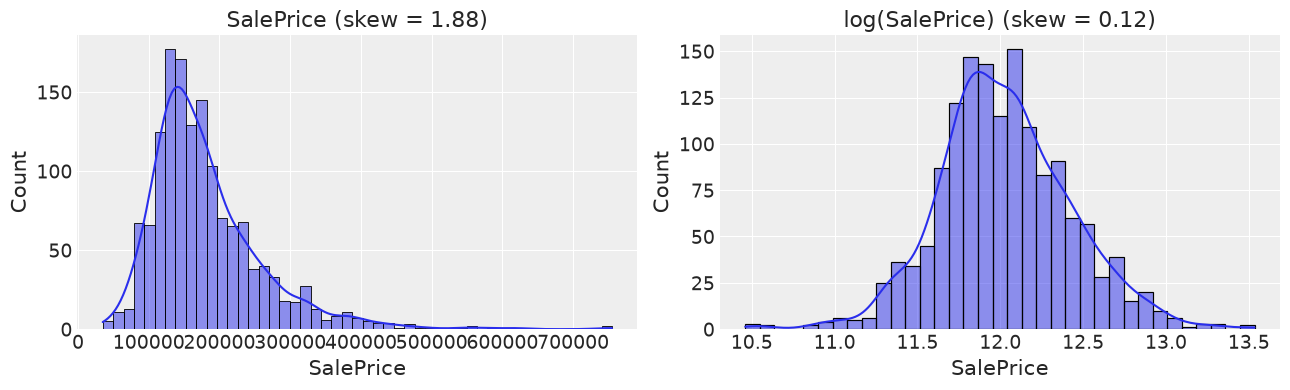

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title(f"SalePrice (skew = {df['SalePrice'].skew():.2f})")
sns.histplot(np.log(df["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title(f"log(SalePrice) (skew = {np.log(df['SalePrice']).skew():.2f})")
plt.tight_layout();

Цена сильно скошена вправо, а её логарифм распределён почти нормально. Поэтому моделируем `log(SalePrice)`:
- нормальное правдоподобие становится уместным;
- метрика соревнования — RMSE в логарифмах (RMSLE), то есть мы оптимизируем ту же величину;
- коэффициенты получают удобную интерпретацию: $e^{\beta}-1$ — **относительное** изменение цены.

In [4]:
num_corr = (df.select_dtypes("number").corr()["SalePrice"]
            .drop(["SalePrice", "Id"]).sort_values(key=np.abs, ascending=False))
num_corr.head(15).to_frame("corr with SalePrice")

,corr with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


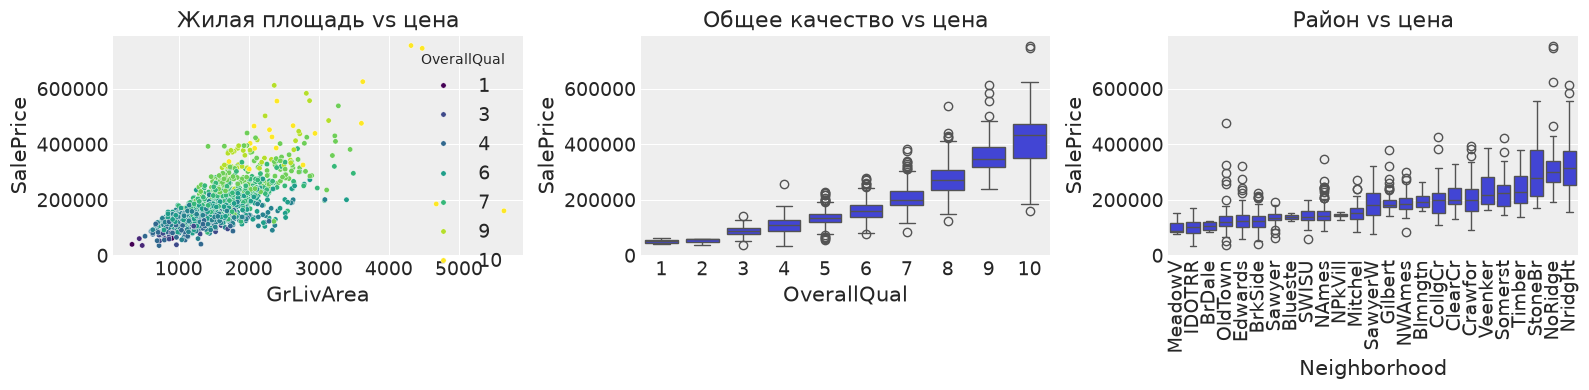

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", s=15, ax=axes[0])
axes[0].set_title("Жилая площадь vs цена")
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[1])
axes[1].set_title("Общее качество vs цена")
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order, ax=axes[2])
axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("Район vs цена")
plt.tight_layout();

На диаграмме рассеяния видны два известных выброса: огромные дома (`GrLivArea > 4000`) с аномально низкой ценой
(частичные продажи недостроенных объектов в Edwards). Авторы датасета (De Cock, 2011) рекомендуют их удалить.
Мы удалим только их, а остальную устойчивость к выбросам обеспечим распределением Стьюдента во второй модели.

## 2. Признаки

Важна интерпретируемость, поэтому берём небольшой набор признаков с ясным смыслом:

| Признак | Смысл | Преобразование |
|---|---|---|
| `GrLivArea` | жилая площадь над землёй, кв. футы | `log` (эластичность) |
| `OverallQual` | общее качество отделки, 1–10 | как числовой |
| `OverallCond` | общее состояние, 1–9 | как числовой |
| `YearBuilt` | год постройки | как числовой |
| `YearRemodAdd` | год последней реконструкции | как числовой |
| `TotalBsmtSF` | площадь подвала | как числовой |
| `GarageCars` | вместимость гаража, машин | как числовой |
| `Fireplaces` | число каминов | как числовой |
| `LotArea` | площадь участка | `log` |
| `CentralAir` | центральное кондиционирование | бинарный (Y = 1) |
| `KitchenQual` | качество кухни | порядковый Po..Ex → 1..5 |
| `Neighborhood` | район (25 уровней) | группа в иерархической модели |

Все числовые признаки стандартизуем по обучающей выборке. Тогда коэффициент — это эффект изменения признака
на одно стандартное отклонение, и коэффициенты можно сравнивать между собой. Кроме того, для стандартизованных
данных легко задать слабоинформативные априорные распределения.

In [6]:
outliers = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300_000)
print("Удаляем выбросы:", df.loc[outliers, ["Id", "GrLivArea", "SalePrice", "Neighborhood"]].to_dict("records"))
data = df.loc[~outliers].copy()

qual_map = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
data["log_GrLivArea"] = np.log(data["GrLivArea"])
data["log_LotArea"] = np.log(data["LotArea"])
data["CentralAir"] = (data["CentralAir"] == "Y").astype(int)
data["KitchenQual"] = data["KitchenQual"].map(qual_map)
data["log_price"] = np.log(data["SalePrice"])

features = ["log_GrLivArea", "OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd",
            "TotalBsmtSF", "GarageCars", "Fireplaces", "log_LotArea", "CentralAir", "KitchenQual"]
print("Пропуски:", data[features + ["Neighborhood"]].isna().sum().sum())

train_df, test_df = train_test_split(data, test_size=0.2, random_state=RANDOM_SEED)
print("train:", train_df.shape[0], " test:", test_df.shape[0])

Удаляем выбросы: [{'Id': 524, 'GrLivArea': 4676, 'SalePrice': 184750, 'Neighborhood': 'Edwards'}, {'Id': 1299, 'GrLivArea': 5642, 'SalePrice': 160000, 'Neighborhood': 'Edwards'}]
Пропуски: 0
train: 1166  test: 292


In [7]:
# стандартизация по train
mu_x, sd_x = train_df[features].mean(), train_df[features].std()
X_train = ((train_df[features] - mu_x) / sd_x).to_numpy()
X_test = ((test_df[features] - mu_x) / sd_x).to_numpy()

y_mean = train_df["log_price"].mean()
y_train = train_df["log_price"].to_numpy()
y_test = test_df["log_price"].to_numpy()

# районы -> целочисленные индексы (все районы из test встречаются в train)
neighborhoods = sorted(data["Neighborhood"].unique())
nb_idx = {n: i for i, n in enumerate(neighborhoods)}
nb_train = train_df["Neighborhood"].map(nb_idx).to_numpy()
nb_test = test_df["Neighborhood"].map(nb_idx).to_numpy()
assert set(test_df["Neighborhood"]) <= set(train_df["Neighborhood"])

coords = {"feature": features, "neighborhood": neighborhoods}
pd.DataFrame(X_train, columns=features).corr().round(2).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,log_GrLivArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,GarageCars,Fireplaces,log_LotArea,CentralAir,KitchenQual
log_GrLivArea,1.000000,0.600000,-0.110000,0.240000,0.300000,0.420000,0.500000,0.450000,0.390000,0.140000,0.430000
OverallQual,0.600000,1.000000,-0.090000,0.560000,0.530000,0.540000,0.590000,0.380000,0.170000,0.270000,0.680000
OverallCond,-0.110000,-0.090000,1.000000,-0.370000,0.080000,-0.180000,-0.190000,-0.020000,-0.000000,0.130000,-0.010000
YearBuilt,0.240000,0.560000,-0.370000,1.000000,0.590000,0.400000,0.550000,0.140000,0.030000,0.390000,0.520000
YearRemodAdd,0.300000,0.530000,0.080000,0.590000,1.000000,0.290000,0.400000,0.090000,0.030000,0.310000,0.630000
TotalBsmtSF,0.420000,0.540000,-0.180000,0.400000,0.290000,1.000000,0.450000,0.310000,0.330000,0.230000,0.430000
GarageCars,0.500000,0.590000,-0.190000,0.550000,0.400000,0.450000,1.000000,0.290000,0.290000,0.250000,0.510000
Fireplaces,0.450000,0.380000,-0.020000,0.140000,0.090000,0.310000,0.290000,1.000000,0.330000,0.190000,0.240000
log_LotArea,0.390000,0.170000,-0.000000,0.030000,0.030000,0.330000,0.290000,0.330000,1.000000,0.080000,0.110000
CentralAir,0.140000,0.270000,0.130000,0.390000,0.310000,0.230000,0.250000,0.190000,0.080000,1.000000,0.270000


## 3. Модель 1: байесовская линейная регрессия

$$
\log(\text{price}_i) \sim \mathcal{N}(\mu_i, \sigma), \qquad
\mu_i = \alpha + \sum_j \beta_j x_{ij}
$$

Априорные распределения (слабоинформативные, на шкале стандартизованных данных):
- $\alpha \sim \mathcal{N}(\bar{y}, 1)$ — средний лог-цены ≈ 12 (около \$160k), ±1 в логарифмах — это разброс цены в $e \approx 2.7$ раза;
- $\beta_j \sim \mathcal{N}(0, 0.2)$ — изменение признака на 1 SD вряд ли меняет цену больше чем на ±50 % ($e^{0.4}\approx1.5$);
- $\sigma \sim \text{HalfNormal}(0.5)$.

Входные данные оборачиваем в `pm.Data`, чтобы потом подставить тестовую выборку и получить предсказания.

In [8]:
def build_linear(X, y):
    with pm.Model(coords=coords) as model:
        X_d = pm.Data("X", X, dims=("obs", "feature"))
        y_d = pm.Data("y", y, dims="obs")
        alpha = pm.Normal("alpha", mu=y_mean, sigma=1.0)
        beta = pm.Normal("beta", mu=0.0, sigma=0.2, dims="feature")
        sigma = pm.HalfNormal("sigma", sigma=0.5)
        mu = pm.Deterministic("mu", alpha + pm.math.dot(X_d, beta), dims="obs")
        pm.Normal("log_price", mu=mu, sigma=sigma, observed=y_d, shape=X_d.shape[0], dims="obs")
    return model

linear_model = build_linear(X_train, y_train)
linear_model

    alpha ~ Normal(12, 1)
     beta ~ Normal(0, 0.2)
    sigma ~ HalfNormal(0, 0.5)
       mu ~ Deterministic(f(alpha, beta))
log_price ~ Normal(mu, sigma)

### 3.1 Prior predictive check

Перед обучением проверим, какие цены модель считает правдоподобными *до* того, как увидит данные.
Разумные априорные распределения должны давать цены одного порядка с реальными, без абсурда вроде \$10 или \$10^9.

Sampling: [alpha, beta, log_price, sigma]


Квантили априорной предсказательной цены (1%, 50%, 99%): [   9000.  150000. 3338000.]


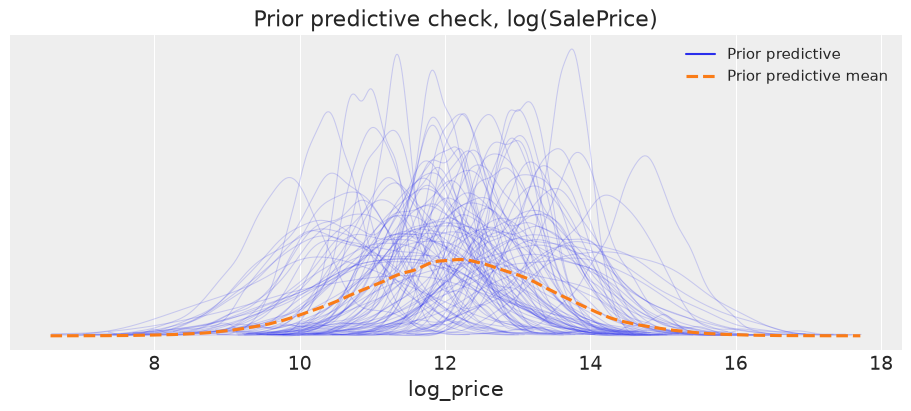

In [9]:
with linear_model:
    prior = pm.sample_prior_predictive(500, random_seed=RANDOM_SEED)

prior_prices = np.exp(prior.prior_predictive["log_price"].values.ravel())
print("Квантили априорной предсказательной цены (1%, 50%, 99%):",
      np.round(np.quantile(prior_prices, [0.01, 0.5, 0.99]), -3))

fig, ax = plt.subplots(figsize=(9, 4))
az.plot_ppc(prior, group="prior", num_pp_samples=100, ax=ax)
ax.set_title("Prior predictive check, log(SalePrice)");

Априорное предсказательное распределение шире данных, но остаётся в правдоподобном диапазоне:
priors слабоинформативны и не навязывают модели результат.

### 3.2 Сэмплирование (NUTS)

In [10]:
with linear_model:
    idata_lin = pm.sample(2000, tune=1000, chains=4, cores=4, target_accept=0.9,
                          random_seed=RANDOM_SEED, idata_kwargs={"log_likelihood": True},
                          progressbar=False)
    idata_lin.extend(pm.sample_posterior_predictive(idata_lin, random_seed=RANDOM_SEED, progressbar=False))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.


Sampling: [log_price]


In [11]:
summary_lin = az.summary(idata_lin, var_names=["alpha", "beta", "sigma"], hdi_prob=0.94)
summary_lin

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,12.023,0.004,12.016,12.031,0.0,0.0,11590.0,5809.0,1.0
beta[log_GrLivArea],0.121,0.005,0.111,0.131,0.0,0.0,9255.0,6196.0,1.0
beta[OverallQual],0.090,0.007,0.077,0.103,0.0,0.0,9614.0,6110.0,1.0
beta[OverallCond],0.053,0.005,0.045,0.062,0.0,0.0,8083.0,6484.0,1.0
beta[YearBuilt],0.088,0.007,0.076,0.100,0.0,0.0,7416.0,6215.0,1.0
beta[YearRemodAdd],0.013,0.006,0.002,0.023,0.0,0.0,8464.0,5673.0,1.0
beta[TotalBsmtSF],0.066,0.005,0.057,0.075,0.0,0.0,10649.0,5714.0,1.0
beta[GarageCars],0.040,0.005,0.030,0.050,0.0,0.0,10403.0,5936.0,1.0
beta[Fireplaces],0.029,0.004,0.020,0.037,0.0,0.0,10789.0,6226.0,1.0
beta[log_LotArea],0.051,0.004,0.043,0.059,0.0,0.0,9856.0,6381.0,1.0


Расхождений (divergences): 0
max r_hat: 1.0  min ess_bulk: 7416.0


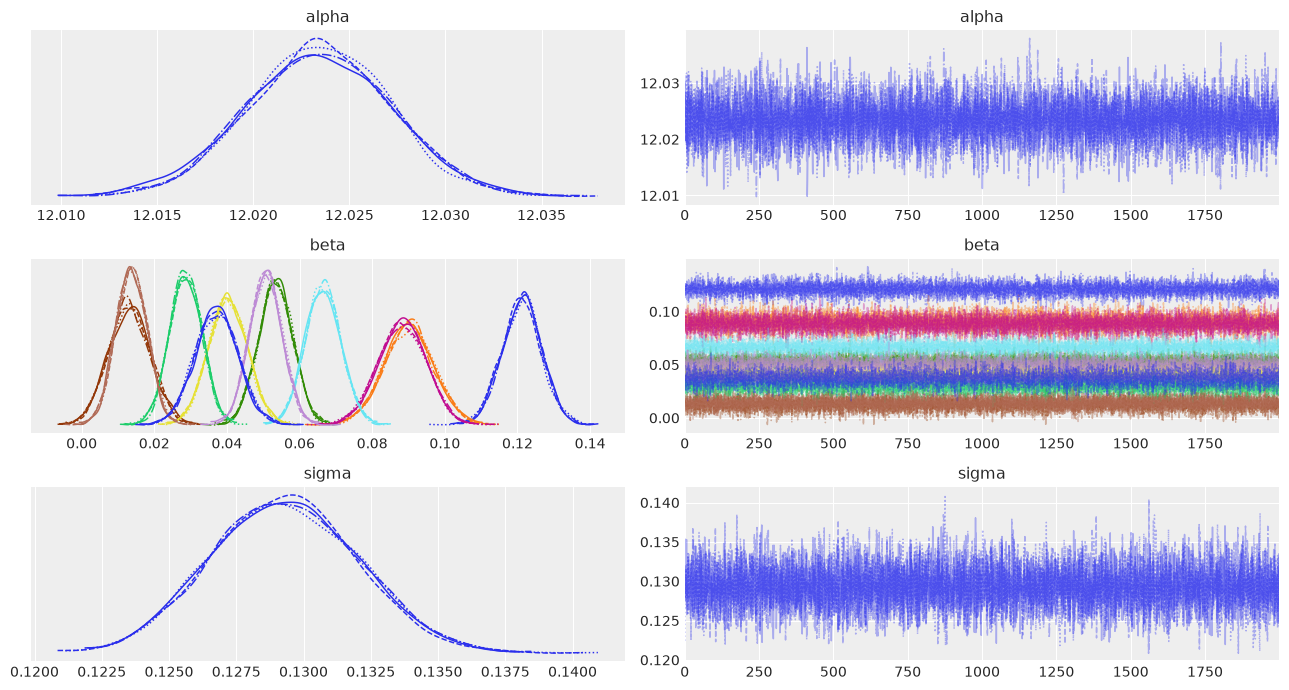

In [12]:
print("Расхождений (divergences):", int(idata_lin.sample_stats["diverging"].sum()))
print("max r_hat:", summary_lin["r_hat"].max(), " min ess_bulk:", summary_lin["ess_bulk"].min())
az.plot_trace(idata_lin, var_names=["alpha", "beta", "sigma"], compact=True, figsize=(13, 7))
plt.tight_layout();

Диагностика сходимости в порядке: $\hat R \approx 1.00$, эффективный размер выборки — тысячи,
расхождений нет, цепочки хорошо перемешаны («мохнатые гусеницы»), апостериорные распределения разных цепочек совпадают.

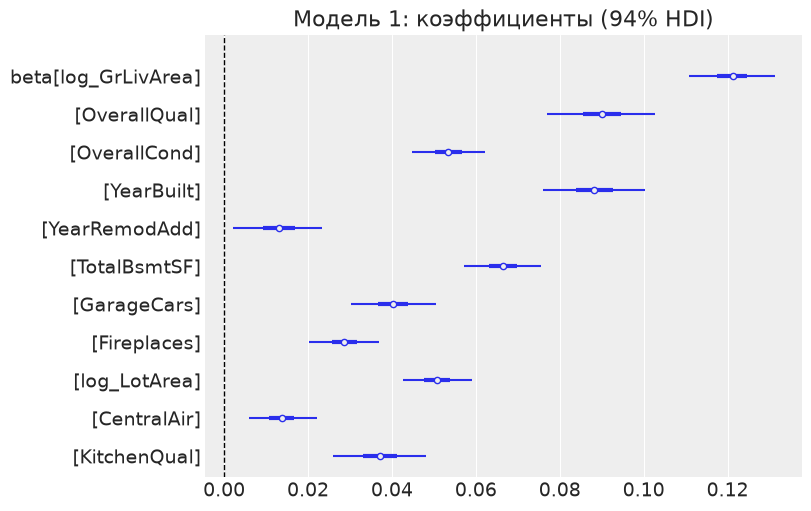

In [13]:
az.plot_forest(idata_lin, var_names=["beta"], combined=True, hdi_prob=0.94, figsize=(8, 5))
plt.axvline(0, color="k", ls="--", lw=1)
plt.title("Модель 1: коэффициенты (94% HDI)");

## 4. Модель 2: иерархическая модель с районами и правдоподобием Стьюдента

Модель 1 не учитывает район, а это главный фактор цены недвижимости («location, location, location»).
25 районов можно закодировать one-hot, но в некоторых районах всего 2–10 продаж, и оценки для них будут шумными.
Байесовский подход позволяет сделать **частичное объединение (partial pooling)**:

$$
\begin{aligned}
\log(\text{price}_i) &\sim \text{StudentT}(\nu, \mu_i, \sigma) \\
\mu_i &= \alpha + a_{\text{nb}[i]} + \sum_j \beta_j x_{ij} \\
a_k &= \tau \cdot z_k, \quad z_k \sim \mathcal{N}(0, 1), \quad \tau \sim \text{HalfNormal}(0.3)
\end{aligned}
$$

- эффекты районов $a_k$ берутся из общего распределения $\mathcal{N}(0, \tau)$. Для малых районов оценка
  «стягивается» к общему среднему, для крупных почти совпадает с выборочной. $\tau$ оценивается по данным;
- используется *non-centered* параметризация ($a = \tau z$), чтобы NUTS не застревал в «воронке Нила»;
- правдоподобие Стьюдента с оцениваемым $\nu \sim \text{Gamma}(2, 0.1)$ имеет тяжёлые хвосты, поэтому
  оставшиеся выбросы (необычные сделки) меньше влияют на коэффициенты.

In [14]:
def build_hier(X, y, nb, likelihood="studentt"):
    with pm.Model(coords=coords) as model:
        X_d = pm.Data("X", X, dims=("obs", "feature"))
        nb_d = pm.Data("nb", nb, dims="obs")
        y_d = pm.Data("y", y, dims="obs")

        alpha = pm.Normal("alpha", mu=y_mean, sigma=1.0)
        beta = pm.Normal("beta", mu=0.0, sigma=0.2, dims="feature")

        tau = pm.HalfNormal("tau", sigma=0.3)
        z = pm.Normal("z", 0.0, 1.0, dims="neighborhood")
        a_nb = pm.Deterministic("a_nb", tau * z, dims="neighborhood")

        sigma = pm.HalfNormal("sigma", sigma=0.5)
        mu = pm.Deterministic("mu", alpha + a_nb[nb_d] + pm.math.dot(X_d, beta), dims="obs")
        if likelihood == "studentt":
            nu = pm.Gamma("nu", alpha=2, beta=0.1)
            pm.StudentT("log_price", nu=nu, mu=mu, sigma=sigma, observed=y_d, shape=X_d.shape[0], dims="obs")
        else:
            pm.Normal("log_price", mu=mu, sigma=sigma, observed=y_d, shape=X_d.shape[0], dims="obs")
    return model

hier_model = build_hier(X_train, y_train, nb_train)

with hier_model:
    idata_hier = pm.sample(2000, tune=1000, chains=4, cores=4, target_accept=0.95,
                           random_seed=RANDOM_SEED, idata_kwargs={"log_likelihood": True},
                           progressbar=False)
    idata_hier.extend(pm.sample_posterior_predictive(idata_hier, random_seed=RANDOM_SEED, progressbar=False))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, tau, z, sigma, nu]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 10 seconds.


Sampling: [log_price]


In [15]:
summary_hier = az.summary(idata_hier, var_names=["alpha", "beta", "tau", "sigma", "nu"], hdi_prob=0.94)
print("Расхождений (divergences):", int(idata_hier.sample_stats["diverging"].sum()))
print("max r_hat:", az.summary(idata_hier, var_names=["~mu"])["r_hat"].max(),
      " min ess_bulk:", az.summary(idata_hier, var_names=["~mu"])["ess_bulk"].min())
summary_hier

Расхождений (divergences): 0


max r_hat: 1.0  min ess_bulk: 1778.0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,12.038,0.012,12.017,12.062,0.000,0.000,1778.0,3051.0,1.0
beta[log_GrLivArea],0.118,0.005,0.109,0.126,0.000,0.000,8261.0,5810.0,1.0
beta[OverallQual],0.075,0.006,0.064,0.085,0.000,0.000,9013.0,6098.0,1.0
beta[OverallCond],0.052,0.004,0.044,0.059,0.000,0.000,6855.0,6169.0,1.0
beta[YearBuilt],0.097,0.007,0.085,0.112,0.000,0.000,5794.0,5762.0,1.0
beta[YearRemodAdd],0.013,0.005,0.005,0.022,0.000,0.000,7546.0,6135.0,1.0
beta[TotalBsmtSF],0.060,0.004,0.052,0.068,0.000,0.000,10473.0,6195.0,1.0
beta[GarageCars],0.037,0.004,0.028,0.045,0.000,0.000,9448.0,6084.0,1.0
beta[Fireplaces],0.023,0.004,0.017,0.030,0.000,0.000,9511.0,6031.0,1.0
beta[log_LotArea],0.057,0.004,0.049,0.066,0.000,0.000,6790.0,6344.0,1.0


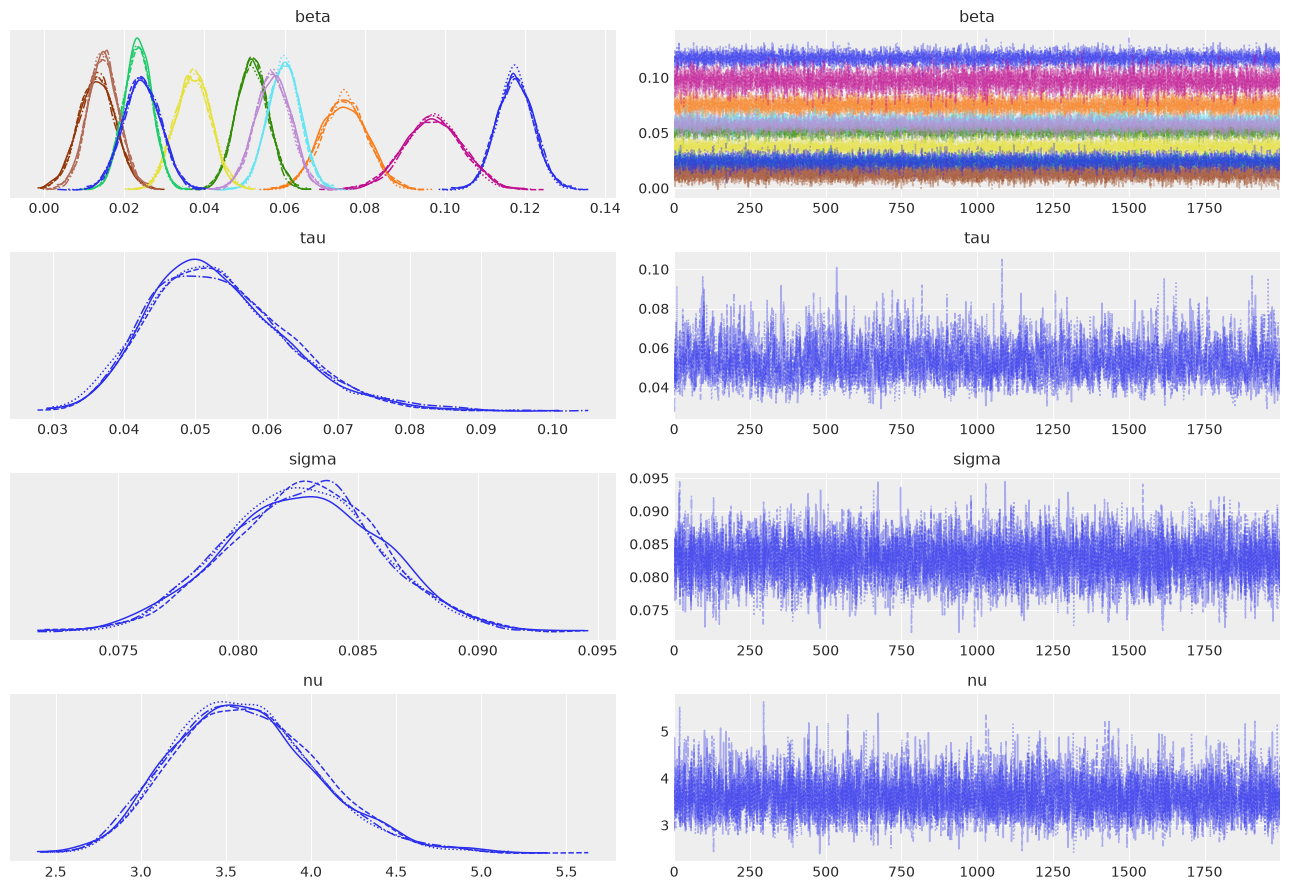

In [16]:
az.plot_trace(idata_hier, var_names=["beta", "tau", "sigma", "nu"], compact=True, figsize=(13, 9))
plt.tight_layout();

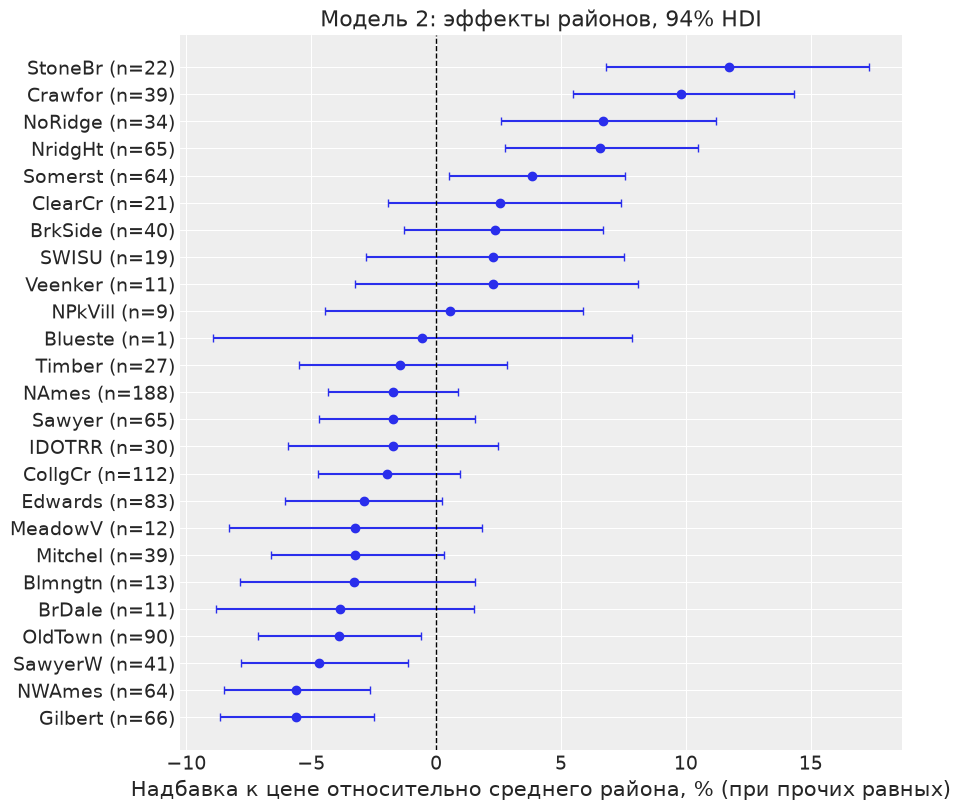

In [17]:
# Эффекты районов: апостериорные средние и 94% HDI, в процентах к цене «среднего» района
a_post = idata_hier.posterior["a_nb"]
a_mean = a_post.mean(("chain", "draw")).to_series()
a_hdi = az.hdi(idata_hier, var_names=["a_nb"], hdi_prob=0.94)["a_nb"].to_pandas()
nb_eff = pd.DataFrame({"effect_%": (np.exp(a_mean) - 1) * 100,
                       "hdi_low_%": (np.exp(a_hdi["lower"]) - 1) * 100,
                       "hdi_high_%": (np.exp(a_hdi["higher"]) - 1) * 100,
                       "n_train": train_df["Neighborhood"].value_counts()}).sort_values("effect_%")

fig, ax = plt.subplots(figsize=(9, 8))
ax.errorbar(nb_eff["effect_%"], range(len(nb_eff)),
            xerr=[nb_eff["effect_%"] - nb_eff["hdi_low_%"], nb_eff["hdi_high_%"] - nb_eff["effect_%"]],
            fmt="o", capsize=3)
ax.set_yticks(range(len(nb_eff)))
ax.set_yticklabels([f"{n} (n={c})" for n, c in zip(nb_eff.index, nb_eff["n_train"])])
ax.axvline(0, color="k", ls="--", lw=1)
ax.set_xlabel("Надбавка к цене относительно среднего района, % (при прочих равных)")
ax.set_title("Модель 2: эффекты районов, 94% HDI");

### 4.1 Иллюстрация partial pooling

Сравним эффект района из иерархической модели с «наивной» оценкой без объединения:
средний остаток модели 1 внутри района. Для маленьких районов иерархическая оценка заметно ближе к нулю (сжатие).

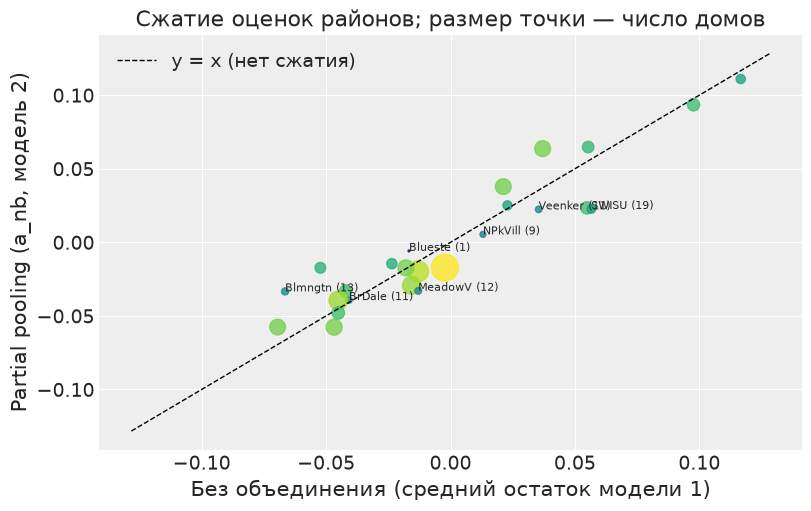

In [18]:
resid_lin = y_train - idata_lin.posterior["mu"].mean(("chain", "draw")).values
no_pool = pd.Series(resid_lin).groupby(train_df["Neighborhood"].values).mean()
cmp_pool = pd.DataFrame({"no_pooling": no_pool, "partial_pooling": a_mean,
                         "n": train_df["Neighborhood"].value_counts()})
cmp_pool["no_pooling"] -= cmp_pool["no_pooling"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(cmp_pool["no_pooling"], cmp_pool["partial_pooling"], s=cmp_pool["n"] * 2,
                c=np.log(cmp_pool["n"]), cmap="viridis", alpha=0.8)
lim = np.abs(cmp_pool[["no_pooling", "partial_pooling"]]).values.max() * 1.1
ax.plot([-lim, lim], [-lim, lim], "k--", lw=1, label="y = x (нет сжатия)")
for n, r in cmp_pool[cmp_pool["n"] < 20].iterrows():
    ax.annotate(f"{n} ({int(r['n'])})", (r["no_pooling"], r["partial_pooling"]), fontsize=8)
ax.set_xlabel("Без объединения (средний остаток модели 1)")
ax.set_ylabel("Partial pooling (a_nb, модель 2)")
ax.set_title("Сжатие оценок районов; размер точки — число домов")
ax.legend();

## 5. Оценка и сравнение моделей

### 5.1 Posterior predictive check

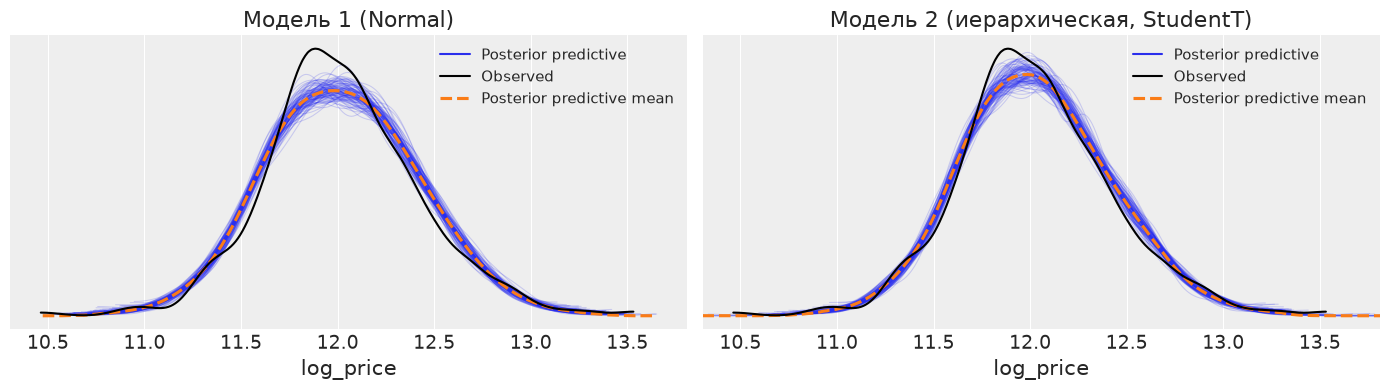

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
az.plot_ppc(idata_lin, num_pp_samples=100, ax=axes[0])
axes[0].set_title("Модель 1 (Normal)")
az.plot_ppc(idata_hier, num_pp_samples=100, ax=axes[1])
axes[1].set_title("Модель 2 (иерархическая, StudentT)")
axes[1].set_xlim(axes[0].get_xlim())
plt.tight_layout();

### 5.2 Сравнение по PSIS-LOO

Оценка ожидаемой предсказательной точности (ELPD) приближённой leave-one-out кросс-валидацией без переобучения моделей.
Чтобы разделить вклад иерархии по районам и тяжёлых хвостов, добавим промежуточную модель:
иерархическую с нормальным правдоподобием (абляция).

In [20]:
hier_norm_model = build_hier(X_train, y_train, nb_train, likelihood="normal")
with hier_norm_model:
    idata_hn = pm.sample(2000, tune=1000, chains=4, cores=4, target_accept=0.95,
                         random_seed=RANDOM_SEED, idata_kwargs={"log_likelihood": True}, progressbar=False)
print("Расхождений:", int(idata_hn.sample_stats["diverging"].sum()),
      " max r_hat:", az.summary(idata_hn, var_names=["~mu"])["r_hat"].max())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, tau, z, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 7 seconds.


Расхождений: 0  max r_hat: 1.0


In [21]:
cmp = az.compare({"1_linear": idata_lin, "1b_hierarchical_normal": idata_hn, "2_hierarchical_t": idata_hier}, ic="loo")
cmp

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
2_hierarchical_t,0,887.581510,37.827358,0.000000,8.981880e-01,34.859651,0.000000,False,log
1b_hierarchical_normal,1,780.673229,37.069320,106.908280,1.018120e-01,47.325378,25.592962,False,log
1_linear,2,722.367996,17.198678,165.213514,5.415025e-15,45.521285,25.559686,False,log


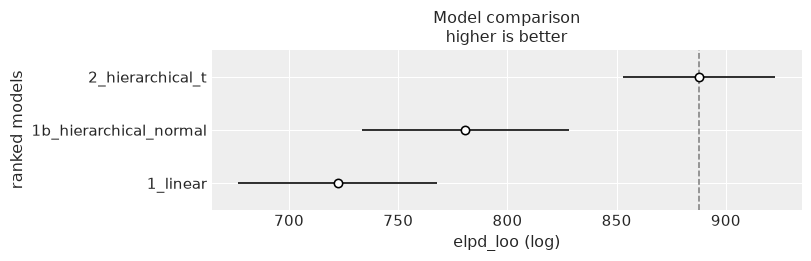

In [22]:
az.plot_compare(cmp, figsize=(8, 2.5));

### 5.3 Качество на отложенной выборке

Подставляем тестовые данные через `pm.set_data` и сэмплируем апостериорное предсказательное распределение.
Точечный прогноз — апостериорное среднее `mu`. Для неопределённости считаем долю тестовых объектов,
попавших в 94%-й предсказательный интервал (калибровка).

Для сравнения обучаем обычную OLS-регрессию на тех же признаках (район в OLS — one-hot).

In [23]:
def predict(model, idata, X, nb=None):
    with model:
        new = {"X": X, "y": np.zeros(len(X))}
        if nb is not None:
            new["nb"] = nb
        pm.set_data(new)
        ppc = pm.sample_posterior_predictive(idata, var_names=["mu", "log_price"],
                                             predictions=True, random_seed=RANDOM_SEED, progressbar=False)
    mu = ppc.predictions["mu"].mean(("chain", "draw")).values
    draws = ppc.predictions["log_price"].stack(s=("chain", "draw")).values
    lo, hi = np.quantile(draws, [0.03, 0.97], axis=1)
    return mu, lo, hi

pred_lin, lo_lin, hi_lin = predict(linear_model, idata_lin, X_test)
pred_hn, lo_hn, hi_hn = predict(hier_norm_model, idata_hn, X_test, nb_test)
pred_hier, lo_hier, hi_hier = predict(hier_model, idata_hier, X_test, nb_test)

# Baseline: OLS
Xo_train = np.hstack([X_train, pd.get_dummies(train_df["Neighborhood"]).reindex(columns=neighborhoods, fill_value=0).values[:, 1:]])
Xo_test = np.hstack([X_test, pd.get_dummies(test_df["Neighborhood"]).reindex(columns=neighborhoods, fill_value=0).values[:, 1:]])
ols_plain = LinearRegression().fit(X_train, y_train)
ols_nb = LinearRegression().fit(Xo_train, y_train)

def metrics(name, pred, lo=None, hi=None):
    rmsle = np.sqrt(mean_squared_error(y_test, pred))
    mae_usd = np.mean(np.abs(np.exp(pred) - np.exp(y_test)))
    cov = np.mean((y_test >= lo) & (y_test <= hi)) if lo is not None else np.nan
    return {"model": name, "RMSLE": rmsle, "R2 (log)": r2_score(y_test, pred),
            "MAE, $": mae_usd, "coverage 94%": cov}

results = pd.DataFrame([
    metrics("OLS (без районов)", ols_plain.predict(X_test)),
    metrics("Bayes 1: linear Normal", pred_lin, lo_lin, hi_lin),
    metrics("OLS + one-hot районы", ols_nb.predict(Xo_test)),
    metrics("Bayes 1b: hierarchical Normal", pred_hn, lo_hn, hi_hn),
    metrics("Bayes 2: hierarchical StudentT", pred_hier, lo_hier, hi_hier),
]).set_index("model")
results.style.format({"RMSLE": "{:.4f}", "R2 (log)": "{:.4f}", "MAE, $": "{:,.0f}", "coverage 94%": "{:.3f}"})

Sampling: [log_price]


Sampling: [log_price]


Sampling: [log_price]


,RMSLE,R2 (log),"MAE, $",coverage 94%
model,,,,
OLS (без районов),0.1336,0.8941,"17,179",nan
Bayes 1: linear Normal,0.1336,0.8941,"17,178",0.949
OLS + one-hot районы,0.1266,0.9049,"15,778",nan
Bayes 1b: hierarchical Normal,0.1266,0.9049,"15,777",0.935
Bayes 2: hierarchical StudentT,0.1299,0.8999,"15,713",0.938


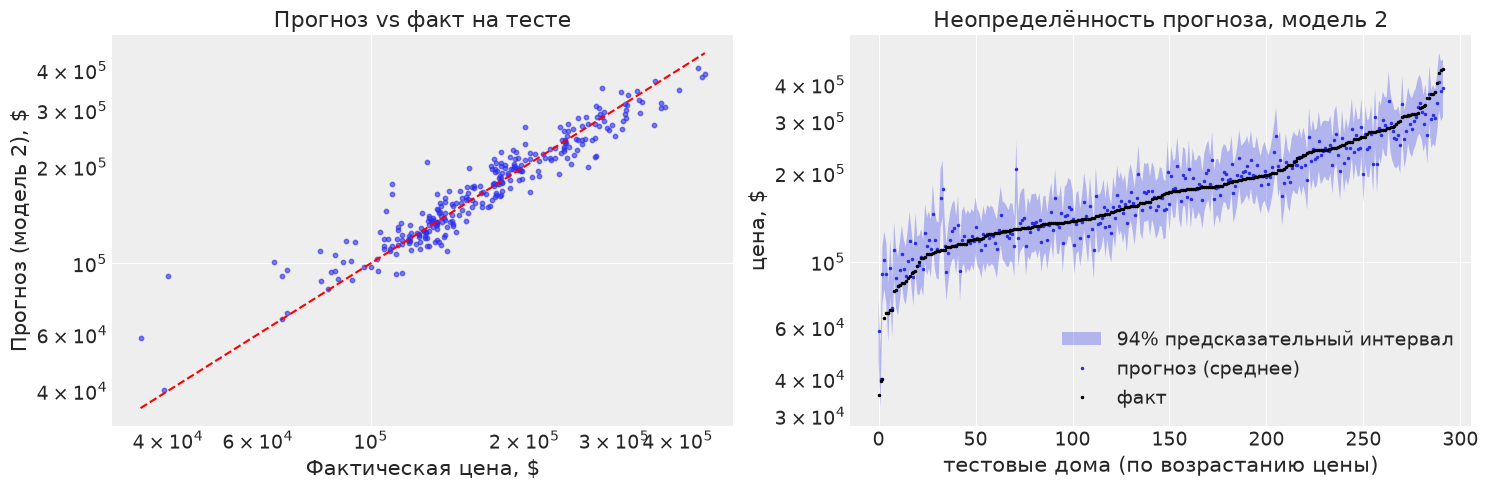

In [24]:
order_ = np.argsort(y_test)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(np.exp(y_test), np.exp(pred_hier), s=10, alpha=0.6)
lims = [np.exp(y_test).min(), np.exp(y_test).max()]
axes[0].plot(lims, lims, "r--")
axes[0].set(xlabel="Фактическая цена, $", ylabel="Прогноз (модель 2), $", xscale="log", yscale="log",
            title="Прогноз vs факт на тесте")
axes[1].fill_between(range(len(y_test)), np.exp(lo_hier[order_]), np.exp(hi_hier[order_]),
                     alpha=0.3, label="94% предсказательный интервал")
axes[1].plot(np.exp(pred_hier[order_]), ".", ms=3, label="прогноз (среднее)")
axes[1].plot(np.exp(y_test[order_]), "k.", ms=3, label="факт")
axes[1].set(yscale="log", xlabel="тестовые дома (по возрастанию цены)", ylabel="цена, $",
            title="Неопределённость прогноза, модель 2")
axes[1].legend()
plt.tight_layout();

## 6. Интерпретация

Модель для логарифма цены, поэтому $e^{\beta_j}-1$ — **на сколько процентов меняется цена** при увеличении
признака $j$ на одно стандартное отклонение при прочих равных (и при том же районе). Пересчитаем также эффект
на «натуральную» единицу признака (+1 балл качества, +1 машиноместо, +10 лет и т. д.).

In [25]:
beta_post = idata_hier.posterior["beta"].stack(s=("chain", "draw")).to_pandas().T  # draws x features
natural_unit = {"log_GrLivArea": None, "OverallQual": 1, "OverallCond": 1, "YearBuilt": 10,
                "YearRemodAdd": 10, "TotalBsmtSF": 100, "GarageCars": 1, "Fireplaces": 1,
                "log_LotArea": None, "CentralAir": 1, "KitchenQual": 1}
unit_desc = {"log_GrLivArea": "+10% жилой площади", "OverallQual": "+1 балл", "OverallCond": "+1 балл",
             "YearBuilt": "+10 лет новее", "YearRemodAdd": "реконструкция на 10 лет позже",
             "TotalBsmtSF": "+100 кв. футов подвала", "GarageCars": "+1 машиноместо",
             "Fireplaces": "+1 камин", "log_LotArea": "+10% площади участка",
             "CentralAir": "есть кондиционер", "KitchenQual": "+1 уровень качества кухни"}

rows = []
for f in features:
    b = beta_post[f].values
    if natural_unit[f] is None:          # лог-признак: эластичность, эффект от +10%
        per_unit = b / sd_x[f] * np.log(1.1)
    else:
        per_unit = b / sd_x[f] * natural_unit[f]
    pct_sd, pct_unit = (np.exp(b) - 1) * 100, (np.exp(per_unit) - 1) * 100
    lo, hi = np.quantile(pct_unit, [0.03, 0.97])
    rows.append({"признак": f, "изменение": unit_desc[f],
                 "эффект на 1 SD, %": pct_sd.mean(),
                 "эффект на единицу, %": pct_unit.mean(), "94% интервал": f"[{lo:.1f}; {hi:.1f}]",
                 "P(эффект > 0)": (b > 0).mean()})
interp = pd.DataFrame(rows).set_index("признак").sort_values("эффект на 1 SD, %", ascending=False)
interp.style.format({"эффект на 1 SD, %": "{:+.1f}", "эффект на единицу, %": "{:+.2f}", "P(эффект > 0)": "{:.3f}"})

,изменение,"эффект на 1 SD, %","эффект на единицу, %",94% интервал,P(эффект > 0)
признак,,,,,
log_GrLivArea,+10% жилой площади,+12.5,+3.50,[3.3; 3.8],1.000
YearBuilt,+10 лет новее,+10.2,+3.26,[2.8; 3.7],1.000
OverallQual,+1 балл,+7.8,+5.59,[4.8; 6.4],1.000
TotalBsmtSF,+100 кв. футов подвала,+6.2,+1.46,[1.3; 1.6],1.000
log_LotArea,+10% площади участка,+5.9,+1.07,[0.9; 1.2],1.000
OverallCond,+1 балл,+5.3,+4.76,[4.1; 5.5],1.000
GarageCars,+1 машиноместо,+3.8,+5.08,[3.9; 6.3],1.000
KitchenQual,+1 уровень качества кухни,+2.5,+3.79,[2.4; 5.2],1.000
Fireplaces,+1 камин,+2.4,+3.70,[2.6; 4.8],1.000


In [26]:
elast = beta_post["log_GrLivArea"] / sd_x["log_GrLivArea"]
print(f"Эластичность цены по жилой площади: {elast.mean():.3f} "
      f"(94% интервал {np.quantile(elast, 0.03):.3f} – {np.quantile(elast, 0.97):.3f})")
print(f"tau (разброс районов): {idata_hier.posterior['tau'].mean().item():.3f}  ->  "
      f"типичный район отличается от среднего на ±{(np.exp(idata_hier.posterior['tau'].mean().item())-1)*100:.0f}%")
print(f"nu (степени свободы StudentT): {idata_hier.posterior['nu'].mean().item():.1f}")
print(f"sigma: модель 1 = {idata_lin.posterior['sigma'].mean().item():.3f}, "
      f"модель 2 = {idata_hier.posterior['sigma'].mean().item():.3f}")

Эластичность цены по жилой площади: 0.361 (94% интервал 0.336 – 0.388)
tau (разброс районов): 0.053  ->  типичный район отличается от среднего на ±5%
nu (степени свободы StudentT): 3.6
sigma: модель 1 = 0.129, модель 2 = 0.083


### Пример: прогноз с неопределённостью для одного дома

Байесовская модель возвращает не одно число, а распределение возможных цен. Его можно использовать
для принятия решений, например оценить вероятность того, что дом стоит дороже заданной суммы.

Sampling: [log_price]


{'Neighborhood': 'NoRidge', 'GrLivArea': 1923, 'OverallQual': 7, 'YearBuilt': 1992, 'GarageCars': 2, 'SalePrice': 190000}
Медиана прогноза: $224,294; 94% интервал: $178,354 – $279,073
P(цена > $200,000) = 0.87


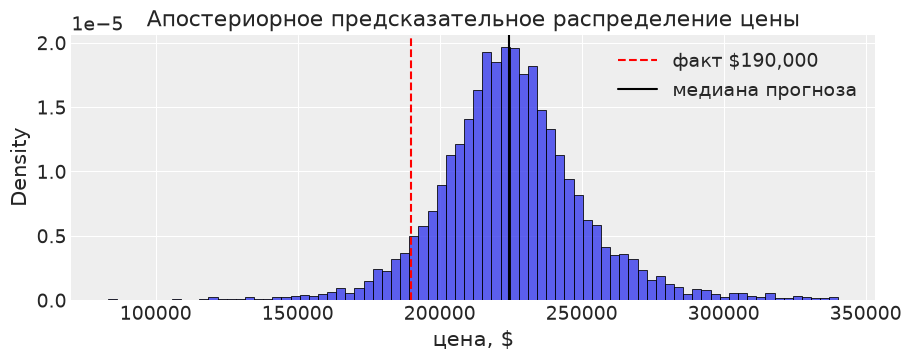

In [27]:
i = 0
house = test_df.iloc[i]
with hier_model:
    pm.set_data({"X": X_test[i:i+1], "nb": nb_test[i:i+1], "y": np.zeros(1)})
    one = pm.sample_posterior_predictive(idata_hier, var_names=["log_price"], predictions=True,
                                         random_seed=RANDOM_SEED, progressbar=False)
price_draws = np.exp(one.predictions["log_price"].values.ravel())
price_draws = price_draws[price_draws < np.quantile(price_draws, 0.995)]

print(house[["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "GarageCars", "SalePrice"]].to_dict())
thr = 200_000
print(f"Медиана прогноза: ${np.median(price_draws):,.0f}; 94% интервал: "
      f"${np.quantile(price_draws, 0.03):,.0f} – ${np.quantile(price_draws, 0.97):,.0f}")
print(f"P(цена > ${thr:,}) = {(price_draws > thr).mean():.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(price_draws, bins=80, stat="density", ax=ax)
ax.axvline(house["SalePrice"], color="r", ls="--", label=f"факт ${house['SalePrice']:,.0f}")
ax.axvline(np.median(price_draws), color="k", label="медиана прогноза")
ax.set(xlabel="цена, $", title="Апостериорное предсказательное распределение цены")
ax.legend();

## 7. Выводы

**Данные и постановка.** Задачу регрессии цены дома решали для `log(SalePrice)`: распределение логарифма почти нормальное,
логарифмическая шкала совпадает с метрикой соревнования (RMSLE), а коэффициенты читаются как процентные эффекты.
Взяли 11 понятных признаков и район. Удалили 2 документированных выброса.
Вместо устаревшего PyMC3 использовали PyMC 5, его преемника с тем же API.

**Построенные модели.**
1. *Байесовская линейная регрессия* (Normal) со слабоинформативными priors. Prior predictive check показал разумный
   априорный диапазон цен (медиана ≈ \$150k, 1–99 % ≈ \$9k – \$3.3M), то есть priors не навязывают результат.
2. *Иерархическая модель*: свой intercept для каждого из 25 районов с частичным объединением (partial pooling)
   и правдоподобие Стьюдента с оцениваемым числом степеней свободы.
3. Промежуточная модель для абляции: иерархическая модель с нормальным правдоподобием.

Во всех моделях NUTS сошёлся без проблем: 0 расхождений, $\hat R = 1.00$, эффективный размер выборки — тысячи. Non-centered параметризация
эффектов районов убрала «воронку» иерархической модели.

**Качество.**
- По PSIS-LOO иерархическая модель со Стьюдентом заметно лучше остальных: ELPD 888 против 781 (иерархическая Normal)
  и 722 (линейная). Разница ≈ 107 ± 26 и 165 ± 26, это 4–6 стандартных ошибок.
- Оценка $\nu \approx 3.6$ означает очень тяжёлые хвосты остатков: даже после удаления двух известных выбросов
  в данных много нетипичных сделок (продажи с торгов, между родственниками и т. п.). Типичный разброс
  при этом $\sigma \approx 0.083$ (≈ ±8.7 % цены) против 0.129 у нормальной модели.
- На отложенной выборке (292 дома): RMSLE 0.134 (модель 1) → 0.127 (иерархическая Normal) → 0.130 (иерархическая StudentT),
  $R^2 \approx 0.90$ в логарифмах. Средняя абсолютная ошибка в долларах лучше всего у модели со Стьюдентом (≈ \$15.7k).
  Модель со Стьюдентом чуть проигрывает по RMSLE, потому что она сознательно «не тянется» за выбросами, а RMSE штрафует
  ошибки на них квадратично. Для типичного дома её прогноз точнее, что подтверждают MAE и LOO.
- По точности точечного прогноза байесовские модели совпадают с OLS: при слабоинформативных priors и 1166 наблюдениях
  данные доминируют, и апостериорное среднее почти равно МНК-оценке. Преимущество байесовского подхода не в точечной
  точности, а в том, что описано ниже.
- **Неопределённость откалибрована:** 94 % предсказательные интервалы покрывают 94–95 % тестовых цен.
  Для каждого дома есть полное распределение цены, по которому можно оценить, например, $P(\text{цена} > \$200k)$.

**Интерпретация (модель 2, при прочих равных и в том же районе):**
- жилая площадь — главный фактор: эластичность ≈ 0.36, то есть +10 % площади дают ≈ +3.5 % цены;
- +1 балл общего качества (`OverallQual`) → ≈ +5.6 %, +1 балл состояния (`OverallCond`) → ≈ +4.8 %;
- дом на 10 лет новее → ≈ +3.3 %; более поздняя реконструкция даёт слабый эффект (+0.6 % за 10 лет);
- +1 машиноместо в гараже → ≈ +5 %, наличие центрального кондиционера → ≈ +6 %, +1 камин → ≈ +3.7 %,
  +1 уровень качества кухни → ≈ +3.8 %, +100 кв. футов подвала → ≈ +1.5 %, +10 % площади участка → ≈ +1.1 %;
- у всех коэффициентов $P(\beta > 0) \approx 1$: направление влияния определено надёжно, и 94 % интервалы узкие.

**Районы.** Разброс «чистых» эффектов районов $\tau \approx 0.05$: после учёта качества, площади и возраста район
добавляет к цене в среднем лишь ±5 %, потому что бо́льшая часть «эффекта района» объясняется тем, какие там дома.
Даже при одинаковых характеристиках StoneBr, Crawfor, NoRidge и NridgHt дороже среднего на 7–12 %,
а Gilbert, NWAmes и SawyerW дешевле на 5–6 %. Частичное объединение работает как ожидалось: оценки малых районов
(Blueste с 1 домом, NPkVill, Veenker, BrDale) стянуты к общему среднему и имеют широкие интервалы, а не получают
экстремальные значения по нескольким сделкам.

**Итог.** Байесовская иерархическая модель с правдоподобием Стьюдента — простая (12 коэффициентов + эффекты районов)
и полностью интерпретируемая. По точности она не уступает классической регрессии ($R^2 \approx 0.90$, RMSLE ≈ 0.13),
но дополнительно даёт откалиброванную неопределённость прогнозов и коэффициентов, устойчива к выбросам
и корректно работает с малыми группами. Возможные улучшения: больше признаков (качество подвала, бассейн, тип продажи
`SaleCondition` как отдельный эффект), взаимодействия «район × площадь» (varying slopes), регуляризующие
horseshoe-priors для отбора признаков из полного набора.